# Práctica: Construcción de un modelo URDF

## Objetivo

Construir un modelo cinemático del manipulador **SO-100** a partir de las piezas STL proporcionadas, organizarlas y orientarlas en Blender, identificar las transformaciones entre sistemas de referencia y describir la estructura del robot mediante un archivo **URDF**. Finalmente, visualizar y verificar el modelo en VS Code mediante la extensión **URDF Visualizer**.

## Rúbrica de evaluación

### Metas

Que el alumno:

- Haga uso de funciones básicas de Blender
- Obtenga información a partir del modelo STL de un robot
- Visualice las transformaciones entre sistemas de referencia y las distinga de transformaciones de elementos visuales
- Construya un modelo URDF a partir de la información obtenida


### Contribución al perfil del egresado

La siguiente práctica contribuye en los siguientes puntos al perfil del egresado:


#### Aptitudes y habilidades

- Para diseñar, construir, operar y mantener los sistemas mecatrónicos y sus componentes.
- Para crear, innovar o evaluar las tecnologías relacionadas con la mecatrónica.


#### Actitudes profesionales

- Ser creativo e innovador.
- Tener confianza en su preparación académica.
- Comprometido con su actualización, superación y competencia profesional.


#### Actitudes de tipo social

- Promover el cambio en la mentalidad frente a la competitividad internacional.


### La evaluación de la práctica contará de los siguientes puntos

| Elemento | Porcentaje |
| ------:| ----------- |
| **Cuestionario previo** | 15% | 
| **Desarrollo** | 35% |
| **Análisis de resultados**  | 35% |
| **Conclusiones** | 15% |


### Se evaluará con los siguientes criterios:

| Elemento | Malo | Regular | Bueno |
| ------: | ------ | -------- | ------ |
| **Cuestionario previo** | El trabajo no contiene cuestionario previo o todas las preguntas son incorrectas (0%) | Al menos la mitad de las preguntas son correctas (8%) | Todas las preguntas son correctas (15%) |
| **Desarrollo** | El trabajo no contiene desarrollo o su planteamiento no concuerda con lo deseado (0%) | El desarrollo está mal planteado o no llega a los resultados esperados (10%) | El desarrollo tiene un planteamiento adecuado y llega a los resultados esperados (35%) |
| **Análisis de resultados** | El trabajo no contiene análisis de resultados o la información no se está interpretando correctamente (0%) | La interpretación de los resultados es parcial o desorganizada (10%) | Realiza un correcto análisis de los resultados de forma organizada (35%) |
| **Conclusiones** | El trabajo no contiene conclusiones o no hacen referencia al trabajo desarrollado y los objetivos planteados (0%) | La redacción de las conclusiones es desorganizada o confusa (8%) | Las conclusiones del trabajo son claras y hacen referencia al trabajo desarrollado y los objetivos planteados (15%) |


## Introducción

### Modelo geométrico y cinemático de un robot

Para describir un robot manipulador en ROS, se utiliza con frecuencia el formato **URDF (Unified Robot Description Format)**. Un archivo URDF es un documento XML que representa el robot como un conjunto de **eslabones** (*links*) conectados mediante **articulaciones** (*joints*). Cada eslabón puede incluir geometría visual, geometría de colisión y propiedades inerciales; cada junta define cómo se conecta un eslabón hijo con uno padre, el tipo de movimiento permitido y la pose relativa entre ambos sistemas de referencia.

Los tipos de junta más comunes son `fixed` (sin movimiento relativo), `revolute` (rotación limitada alrededor de un eje), `continuous` (rotación sin límites angulares) y `prismatic` (traslación). En un manipulador como el SO-100, las articulaciones de los motores se representan normalmente como articulaciones rotacionales. La etiqueta `origin` expresa la transformación entre los marcos de la junta padre e hijo mediante `xyz` (traslación) y `rpy` (orientación en ángulos roll, pitch y yaw, en radianes). El eje de movimiento se especifica mediante `axis`; por convención, se expresa en el marco de la junta.

Una descripción URDF no se obtiene únicamente colocando las mallas STL una junto a otra: es necesario determinar correctamente la relación entre los sistemas de referencia. Un error en la orientación de una junta puede hacer que el modelo se vea razonablemente bien, pero que el robot rote alrededor de un eje incorrecto. Por ello, en esta práctica se utilizará Blender para inspeccionar y preparar las piezas y, posteriormente, se describirán las transformaciones en URDF.

### Manejo básico de Blender para preparar piezas robóticas

**Blender** es una herramienta de modelado 3D que permite importar mallas STL, inspeccionar su geometría, transformar objetos y establecer jerarquías padre/hijo. Cada objeto tiene un sistema de referencia local (origen del objeto y ejes locales X, Y y Z), distinto del sistema de coordenadas global de la escena. Para esta práctica, los sistemas locales deben facilitar la interpretación cinemática: el eje **Z local de cada pieza asociada a un motor debe alinearse con el eje de giro de ese motor**.

Las transformaciones de un objeto incluyen ubicación, rotación y escala. En Blender, **Apply Rotation** aplica la rotación actual a los datos de la malla y deja los valores de rotación del objeto en cero, conservando su apariencia en la escena. Esto resulta útil para preparar una geometría cuya orientación debe quedar incorporada en la malla, aunque debe hacerse deliberadamente: aplicar una rotación cambia cómo se interpretan las coordenadas locales de la geometría y puede afectar las transformaciones que luego se documenten en URDF.

En esta práctica, Blender se utilizará para construir un archivo de inspección y organización de las piezas, no para sustituir la definición cinemática del URDF. El modelo final deberá tener una jerarquía coherente y los marcos de referencia necesarios para calcular `origin xyz`, `origin rpy` y `axis`.

## Cuestionario previo

Responder brevemente antes de comenzar:

1. ¿Cuál es la diferencia entre un `link` y un `joint` en URDF?
> Un **link** (eslabón) representa un cuerpo rígido físico del robot (como la base o el hombro) que contiene información de geometría visual, colisión e inercia. Un **joint** (articulación) representa la unión mecánica entre dos eslabones, definiendo el tipo de movimiento relativo permitido entre ellos (revoluto, continuo, prismático o fijo).



2. ¿Qué información se define en las etiquetas `origin`, `axis` y `parent`/`child` de una junta URDF?
> **`origin`** define la posición relativa (`xyz` en metros) y orientación (`rpy` en radianes) del marco hijo respecto al padre; **`axis`** especifica el vector unitario del eje de movimiento para juntas móviles en el marco de la junta; y **`parent` / `child`** establecen la conectividad jerárquica del árbol cinemático del robot.

3. ¿Cuál es la diferencia entre el sistema de coordenadas global y el sistema local de un objeto en Blender?
>  El sistema **global (World)** es un marco de referencia absoluto y fijo para toda la escena tridimensional, mientras que el sistema **local** es propio de cada objeto individual, definido por su origen y sus propios ejes X, Y y Z, los cuales se desplazan y rotan junto con el objeto.

4. ¿Qué hace la operación **Apply Rotation** en blender?
> Toma la rotación actual del objeto en la escena, la aplica de forma permanente directamente sobre los datos geométricos de la malla (vértices) y restablece los valores numéricos de rotación del objeto a cero, preservando su apariencia visual.\n",

5. ¿En qué unidades se especifican las traslaciones y los ángulos en URDF?
> Las traslaciones (especificadas en los atributos `xyz`) se indican en **metros** ($\text{m}$), y los ángulos de orientación (`rpy`) se indican en **radianes** .

## Desarrollo

### 1. Preparación del espacio de trabajo

1. Dentro de la carpeta de la práctica, cree carpetas con la siguiente estructura. Guarde en `meshes/` los STL proporcionados y conserve los nombres de archivo originales cuando sea posible.

```text
practica_2/
├── blender/
│   └── so100_modelo.blend
├── meshes/
│   ├── base.stl
│   └── ... (resto de las piezas proporcionadas)
├── urdf/
│   └── so100.urdf
└── imagenes/
    ├── blender_jerarquia.png
    ├── blender_ejes.png
    ├── ...
    └── urdf_visualizer.png
```

2. Abra Blender y guarde el proyecto como `blender/so100_modelo.blend`.
3. Elimine los objetos iniciales que no vaya a utilizar.
4. Importe los archivos STL mediante **File → Import → STL** ó arrastrándolos hacia el editor de blender desde el explorador de archivos.


**Evidencia:** captura de la escena con todas las piezas importadas y nombres legibles.

![Piezas importadas](imagenes/piezas_importadas.png)

### 2. Mostrar e inspeccionar los sistemas de referencia locales en Blender

1. Para visualizar los sistemas de referencia locales de cada pieza, abrir el menú deplegable de la parte superior derecha **"Viewport Gizmos"** y en la sección "**Object Gizmos**" habilitar *"Move"* y seleccionar en sistemas de referencia *"Local"*

<img src="imagenes/p2_1.png" align="center" alt="Viewport Gizmos" height="500"/>

2. En el menú **"Viewport Overlays"** habilite el eje *"z"* y ajuste la escala de la malla que representa al suelo a **0.001 [m]** (**1 mm**)

<img src="imagenes/p2_2.png" align="center" alt="Viewport Gizmos" height="500"/>
<img src="imagenes/p2_1_1.png" align="center" height="500"/>


3. Seleccione cada pieza y observe dónde está su origen local y cómo están orientados sus ejes. Registre los resultados en una tabla.

| Pieza / eslabón | Corrección necesaria del eje "z"|
|---|---|
| Base| El eje $Z$ local ya apunta verticalmente hacia arriba.No requiere corrección de orientación del eje $Z$ |
| Shoulder rotation pitch | Requiere rotar la pieza $90^\circ$ alrededor del eje $X$ global para que su eje $Z$ quede alineado con el eje concéntrico del eje del motor. |
| Upper Arm | Rotar $-90^\circ$ alrededor del eje $Y$ para que el eje $Z$ quede horizontal y colineal con el barreno de montaje del hombro  |
| Lower Arm | Rotar $-90^\circ$ sobre el eje $Y$ para que el eje $Z$ quede horizontal, atravesando concéntricamente los orificios del codo|
| Wrist pitch roll | Rotar $-90^\circ$ sobre el eje $Y$ para que el eje $Z$ quede horizontal, atravesando concéntricamente los orificios de la horquilla|
| Fixed gripper | Rotar $90^\circ$ alrededor del eje $X$ |
| Moving jaw  | El eje $Z$ ya se encuentra vertical, coincidiendo con la dirección coaxial de giro de los orificios de la mordaza. No requiere corrección de rotación del eje $Z$  |

### 3. Orientar las piezas

La jerarquía en Blender sirve para organizar la escena; por sí sola no define el tipo de junta ni sustituye las transformaciones del URDF.

1. Rote la pieza hasta que el eje Z local asociado al motor coincida con el eje físico de giro. Puede utilizar `R` seguido del eje global o local y un ángulo, o introducir valores numéricos en el panel `N`. Confirme visualmente la alineación desde más de una vista.
4. Si se requiere que la orientación quede incorporada en la geometría, use **Object → Apply → Rotation** (`Ctrl+A` → **Rotation**) solo después de verificar el resultado. La rotación del objeto quedará en cero, pero la malla conservará la orientación visual. No aplique transformaciones de manera indiscriminada: registre qué piezas se modificaron y qué efecto tuvo en los ejes locales.
5. Repita el proceso para las piezas restantes. El eje Z del marco asociado a cada motor debe quedar alineado con el eje de giro correspondiente.
6. Guarde el archivo `.blend`.

**Importante:** no confunda “hacer que la malla se vea alineada” con “definir correctamente el marco de junta”. Para el URDF, además de la orientación de la malla visual, deben definirse de forma explícita el origen y el eje de cada junta. La geometría visual de un eslabón puede requerir una transformación propia respecto al marco del eslabón.

**Evidencias:** captura de una pieza con el eje *"z"* alineado con el eje del motor.


![Piezas orientadas](imagenes/orienta_Z.png)

### 3. Crear relaciones padre/hijo y obtener las transformaciones entre sistemas de referencia

La jerarquía en Blender sirve para organizar la escena; por sí sola no define el tipo de junta ni sustituye las transformaciones del URDF.

1. Determine la secuencia mecánica desde la base hasta el efector final. Para cada conexión, identifique cuál pieza será el padre y cuál el hijo.
2. Para establecer una relación padre/hijo, seleccione primero el objeto hijo, después el padre y presione `Ctrl+P`. Elija **Object (Keep Transform)** para conservar la posición y orientación actuales. Verifique la jerarquía en el *Outliner*. Si la opción o el resultado difieren según la versión, consulte el menú **Object → Parent**.

A partir del modelo preparado, determine para cada junta la transformación del marco padre al marco de la junta/hijo. Registre las traslaciones en metros y las orientaciones en radianes.

Una transformación homogénea se expresa como:
$$

{}^{j}\mathbf{T}_{i}=
\begin{bmatrix}
{}^{j}\mathbf{R}_{i} & {}^{j}\mathbf{p}_{i}\\
\mathbf{0}^{T} & 1
\end{bmatrix}

$$

donde \(P\) representa el marco padre, \(J\) el marco de la junta, \({}^{P}\mathbf{p}_{J}=[x\;y\;z]^T\) es la posición del origen de \(J\) respecto a \(P\), y \({}^{P}\mathbf{R}_{J}\) describe la orientación relativa.

Para cada conexión:

3. Identifique el centro del eje de giro del motor en la pieza padre.
4. Identifique la orientación que debe tener el marco de junta para que su eje Z coincida con el eje del motor.
5. Determine la posición relativa entre el origen del marco padre y el origen de la junta.
6. Exprese la orientación relativa mediante ángulos `roll`, `pitch`, `yaw` (en ese orden y en radianes para el atributo URDF `rpy`). No copie directamente los valores Euler de Blender sin verificar que representan la orientación relativa entre los marcos elegidos.
7. Si el origen del STL está desplazado del eje del motor, calcule la transformación necesaria para ubicar la geometría visual respecto al marco del eslabón. Esta transformación puede ser distinta de la transformación de la junta.

Complete la tabla siguiente. Use una fila por junta y añada filas para todas las articulaciones del SO-100 suministrado.

| Junta | Padre | Hijo | Tipo | `origin xyz` (m) | `origin rpy` (rad) | `axis` |
|---|---|---|---|---|---|---|
| `joint_1` | `base` | `shoulder rotation pitch` | `revolute` | `0 -0.0452 0.016` | `0  0  0` | `0 0 1` |
| `joint_2` | `shoulder rotation pitch` | `Upper Arm` | `revolute` | `0 -0.075898 0.11856` | $0 \quad \pi/2 \quad 0$| `0 0 1` |
| `joint_3` | `Upper Arm` | `Lower Arm` | `revolute` | `0 0.036672 0.14656` | $\pi/2 \quad 0 \quad \pi/2$ | `0 0 1 `|
| `joint_4` | `Lower Arm` | `Wrist Pitch Roll` | `revolute` | `0 -0.098228 0.15074` | $0 \quad \pi/2 \quad 0$ | `0 0 1 `|
| `joint_5` | `Wrist Pitch Roll` | `Fixed Gripper` | `revolute` | `0 -0.1607 0.15075` | $\pi/2 \quad \pi/2 \quad 0$  | `0 0 1 `|
| `joint_6` | `Fixed Gripper` | `Moving Jaw` | `revolute` | `0 -0.18505 0.17103` | $0 \quad -\pi/2 \quad 0$ | `0 0 1 `|

**Evidencias:** captura del *Outliner* con las jerarquías padre/hijo y el modelo del robot construído en blender

![Jerarquías](imagenes/padre-hijo.png)![Armado](imagenes/Armado2.png)
![Armado2](imagenes/Armado1.png)

### 5. Construir el archivo URDF en Visual Studio Code

1. Abra en VS Code la carpeta `construccion_urdf/`.
2. Cree `urdf/so100.urdf`.
3. Declare el robot con una etiqueta raíz `<robot name="so100">`.
4. Defina un `<link>` por cada eslabón físico. Incluya una etiqueta `<visual>` con `<geometry><mesh filename="..."/></geometry>`. Use rutas relativas al archivo URDF, por ejemplo `filename="../meshes/base.stl"`; compruebe que el visualizador resuelva correctamente las rutas. Si la extensión requiere una organización distinta, ajuste las rutas y documente el cambio. Para el nombre de las etiquetas de eslabón, puede usar los nombres de los archivos stl
5. Para cada unión entre eslabones, cree una etiqueta `<joint>` con `name`, `type`, `parent`, `child`, `origin` y `axis`. Añada `limit` para articulaciones `revolute`.
6. Defina la junta raíz con el marco de la base y conecte todas las piezas hasta el gripper. Cada eslabón hijo debe conectarse mediante una junta, y cada eslabón debe tener una única conexión padre dentro del árbol cinemático.
7. Incluya una geometría visual por pieza STL. Si el origen local de la malla no coincide con el marco del eslabón, utilice los atributos `origin xyz` y `origin rpy` dentro de `<visual>` para posicionar la malla, sin confundirlos con los de `<joint>`.
8. Para los archivos STL, revise si las unidades de origen son milímetros. URDF interpreta las coordenadas de `origin xyz` en metros; además, verifique que la escala de las mallas importadas sea coherente. No compense un error de escala con traslaciones.
9. Mantenga el XML bien formado: todas las etiquetas deben cerrarse y los nombres de los `link` usados en `parent` y `child` deben existir.

**Evidencias:**

URDF:
~~~
<robot name="so100">
<!--Información de eslabones-->
<link name="base_link">
    <visual>
        <origin xyz="0.0 0.0 0.0" rpy="0.0 0.0 0.0"/>
        <geometry>
            <mesh filename="Mallas/Base.STL" scale="1 1 1"/>
        </geometry>
        <material name="negro">
            <color rgba="0.0 0.0 0.0 1.0"/>
        </material>
    </visual>
</link>

<link name="shoulder_link">
    <visual>
        <origin xyz="0.0 0.0 0.0" rpy="1.57 0.0 0.0"/>
        <geometry>
            <mesh filename="Mallas/Shoulder_Rotation_Pitch.STL" scale="1.66 1 1"/>
        </geometry>
        <material name="rojo">
            <color rgba="1 0 0.0 1.0"/>
        </material>
    </visual>
</link>

<link name="upper_arm">
    <visual>
        <origin xyz="0.0 0.0 0.0" rpy="0 0.0 0.0"/>
        <geometry>
            <mesh filename="Mallas/Upper_Arm.STL" scale="1.66 1 1"/>
        </geometry>
        <material name="amarillo">
            <color rgba="1 1 0.0 1.0"/>
        </material>
    </visual>
</link>

<link name="lower_arm">
    <visual>
        <origin xyz="0.0 0.0 0.0" rpy="1.5708 0.0 0"/>
        <geometry>
            <mesh filename="Mallas/Lower_Arm.STL" scale="1.66 1 1"/>
        </geometry>
        <material name="verde">
            <color rgba="0 1 0.0 1.0"/>
        </material>
    </visual>
</link>

<link name="wrist_pitch"><!--2.3562-->
    <visual>
        <origin xyz="0.0 0.0 0.0" rpy="0 0 0"/>
        <!--rpy="2.30 0.0 3.141592"-->
        <geometry>
            <mesh filename="Mallas/Wrist_Pitch_Roll.STL" scale="1.66 1 1"/>
        </geometry>
        <material name="blanco">
            <color rgba="1 1.0 1.0 1.0"/>
        </material>
    </visual>
</link>
<link name="fixed_gripper"><!--rpy="1.4 0.0 0.0" -->
    <visual>
        <origin xyz="0 0 0" rpy="0 -1.578 0"/>
        <geometry>
            <mesh filename="Mallas/Fixed_Gripper.STL" scale="1 1 1"/>
        </geometry>
        <material name="cian">
            <color rgba="0 1 1 1.0"/>
        </material>
    </visual>
</link>
<link name="moving_jaw">
    <visual>
        <origin xyz="0 0 0" rpy="0 1.578 0"/>
        <geometry>
            <mesh filename="Mallas/Moving_Jaw.STL" scale="1 1 1"/>
        </geometry>
        <material name="magenta">
            <color rgba="1 0 1 1.0"/>
        </material>
    </visual>
</link>


<!--Información de articulaciones-->

<!-- las articulaciones van en orden así:
    base->shoulder rotation ->upper arm -> lower arm -> 
    wirst ptch roll -> fixed gripper -> moving jaw -->


<joint name="shoulder_joint" type="revolute">
    <origin xyz="0.0 -0.0452 0.016" rpy="0.0 0.0 0.0"/>
    <parent link="base_link"/>
    <child link="shoulder_link"/>
    <axis xyz="0.0 0.0 -1"/>
    <limit lower="-1.745" upper="1.745" effort="1.0" velocity="10.0"/>
</joint>

<joint name="upper_arm_joint" type="revolute">
    <origin xyz="0.0 -0.0306 0.10249" rpy="0.0 0.0 0.0"/>
    <parent link="shoulder_link"/>
    <child link="upper_arm"/>
    <axis xyz="1.0 0.0 0"/>
    <limit lower="-.1745" upper="3.14" effort="1.0" velocity="10.0"/>
</joint>

<joint name="lower_arm_joint" type="revolute">
    <origin xyz="0.0 0.11257 0.028" rpy="0.0 0.0 0.0"/>
    <parent link="upper_arm"/>
    <child link="lower_arm"/>
    <axis xyz="1.0 0.0 0"/>
    <limit lower="-3.14" upper="0" effort="1.0" velocity="10.0"/>
</joint>

<joint name="wirst_pitch_joint" type="revolute">
    <origin xyz="0.0 -0.1349 0.0052" rpy=".7854 0.0 0.0"/>
    <parent link="lower_arm"/>
    <child link="wrist_pitch"/>
    <axis xyz="-1.0 0.0 0"/>
    <limit lower="-1" upper="2.7" effort="1.0" velocity="10.0"/>
</joint>

<joint name="fixed_gripper_joint" type="revolute">
    <origin xyz="0.0 -.0622 0.0" rpy="0 0 0"/>
    <parent link="wrist_pitch"/>
    <child link="fixed_gripper"/>
    <axis xyz="0 1 0"/>  <!-- este es el eje desde la REFERENCIA DEL HIJO-->
    <limit lower="-3.14" upper="3.14" effort="1.0" velocity="10.0"/>
</joint>

<joint name="moving_jaw_joint" type="revolute">
    <origin xyz="0 -.0246 -.020283" rpy="0.0 0.0 0.0"/>
    <parent link="fixed_gripper"/>
    <child link="moving_jaw"/>
    <axis xyz="1 0 0"/>
    <limit lower="-.2" upper=
    "1.57" effort="1.0" velocity="10.0"/>
</joint>


</robot>
~~~


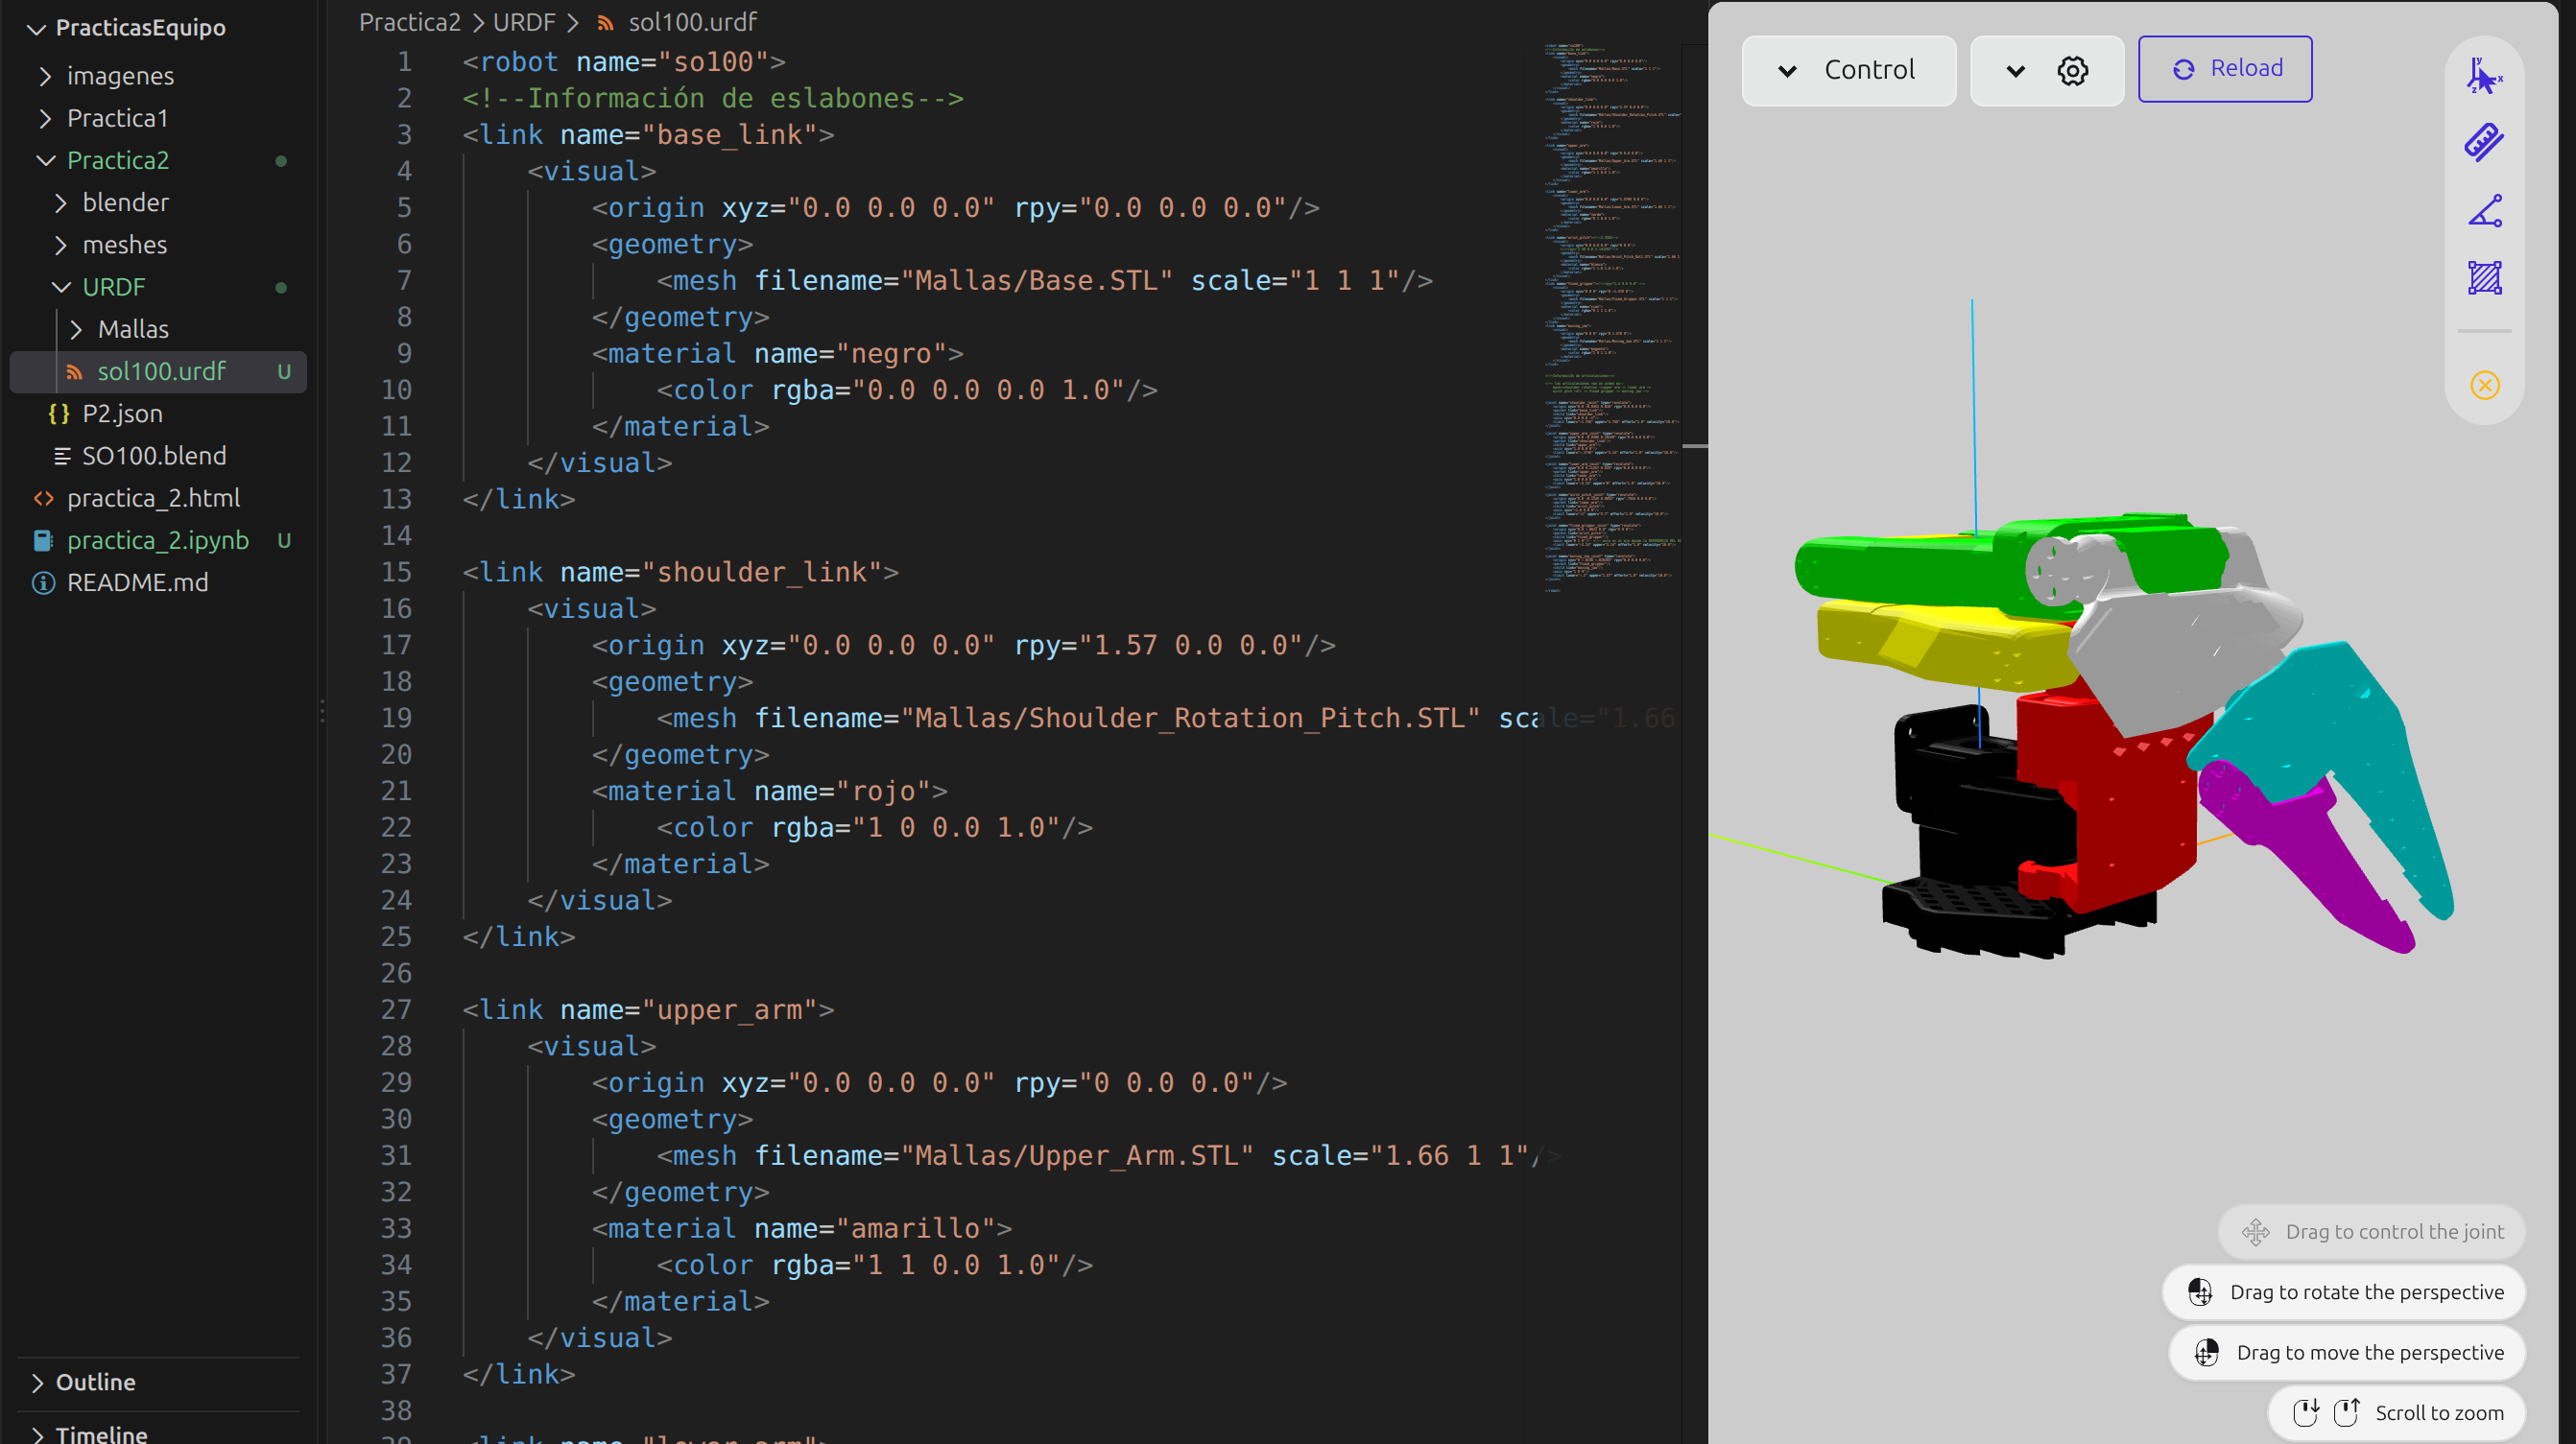

### 6. Visualizar y validar el URDF con URDF Visualizer

4. Compruebe en el visualizador de URDF en VSCode: 
   - Todas las piezas aparecen y tienen una escala razonable.
   - La base está en una posición coherente.
   - Las piezas están conectadas en el orden cinemático correcto.
   - Los ejes de las articulaciones coinciden con los ejes de giro de los motores.
   - Al modificar la posición de una junta desde el visualizador, las piezas hijas se mueven alrededor del eje esperado.
   - No hay piezas inesperadamente desplazadas, giradas o reflejadas.
5. Si una pieza aparece orientada incorrectamente, determine si el error está en la transformación de la junta (`joint/origin`), en la transformación de la malla (`visual/origin`) o en la orientación/escala de la propia malla. Corrija el parámetro correspondiente en vez de introducir compensaciones arbitrarias:

 Junta | Padre | Hijo | Tipo | `origin xyz (hijo respecto al padre)` (m) | `origin rpy (hijo respecto al padre))` (rad) | `axis` |
|---|---|---|---|---|---|---|
| `shoulder_joint` | `base` | `shoulder rotation pitch` | `revolute` | `0 -0.0452 0.016` | `0  0  0` | `0 0 -1` |
| `upper_arm_joint` | `shoulder rotation pitch` | `Upper Arm` | `revolute` | `0.0 -0.0306 0.10249` | `0  0  0`| `1 0 0` |
| `lower_arm_joint` | `Upper Arm` | `Lower Arm` | `revolute` | `0 0.11257 0.028` | `0  0  0` | `1 0 0 `|
| `wirst_pitch_joint` | `Lower Arm` | `Wrist Pitch Roll` | `revolute` | `0.0 -0.1349 0.0052` | $\pi/4 \quad 0 \quad 0$| `1 0 0 `|
| `fixed_gripper_joint` | `Wrist Pitch Roll` | `Fixed Gripper` | `revolute` | `0.0 -.0622 0.0` | `0 0 0`  | `0 1 0 `|
| `moving_jaw_joint` | `Fixed Gripper` | `Moving Jaw` | `revolute` | `0 -.0246 -.020283` | `0 0 0` | `1 0 0 `|
6. Guarde el archivo URDF y las evidencias. Tome una captura del robot completo.

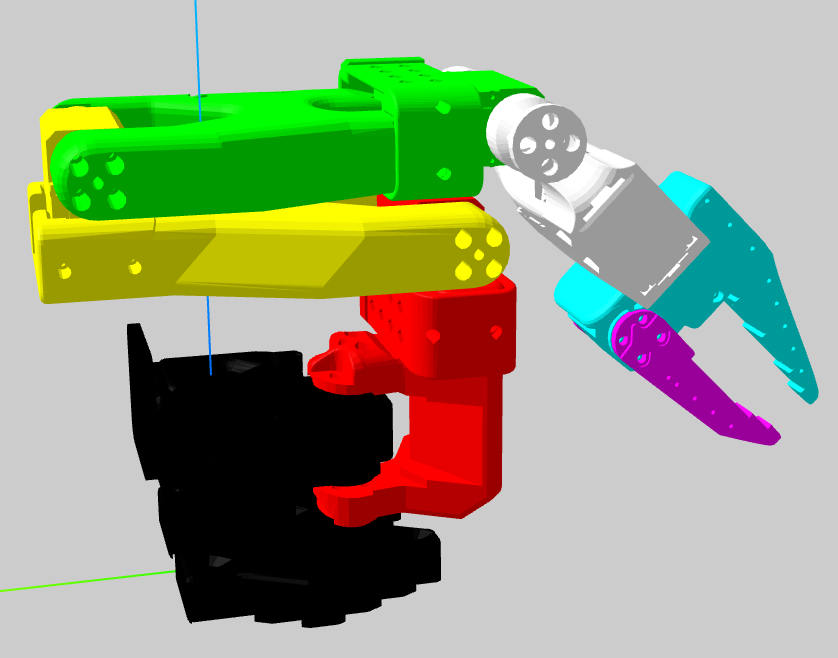

**Entregables del desarrollo**

- Archivo Blender `so100_modelo.blend` con las piezas organizadas, nombres descriptivos y jerarquía padre/hijo.
- Archivo `so100.urdf` con los links, joints, mallas y transformaciones.
- Tabla de transformaciones entre marcos de referencia.
- Capturas de los ejes locales, la jerarquía de Blender y el robot visualizado en VS Code.

## Análisis de resultados

Responder con base en las decisiones y verificaciones realizadas:

1. ¿Qué diferencias hay entre los sistemas de referencia globales y locales de Blender? ¿Cómo los utilizó para identificar los ejes de los motores?
> **RESPUESTA**

2. ¿Qué efecto tuvo aplicar una rotación a la malla y cómo comprobó que no se alteró la interpretación cinemática de las piezas?
> **RESPUESTA**

3. Explique la diferencia entre la transformación definida en `joint/origin` y la definida en `visual/origin`.
> **RESPUESTA**

4. ¿Qué ventajas tiene describir el robot mediante URDF frente a disponer únicamente de un conjunto de modelos STL?
> **RESPUESTA**

## Conclusiones

> **CONCLUSIONES**

## Bibliografía

Incluya las fuentes consultadas en formato IEEE, en caso de haberlas consultado.

> **BIBLIOGRAFÍA**